# 5. Tables and figures for the paper

Reads the result files and writes everything `paper/pqk100_preliminary.tex` includes:

- `paper/figures/*.pdf`
- `paper/tables/*.tex`

Nothing is recomputed here. Rerun notebook 3 first if the results should change.

In [1]:
import os, sys
from pathlib import Path
# Find the project folder (the one holding the pqk100 package), wherever Jupyter or VS Code started
def _find_root():
    starts = [Path(p).parent for p in [globals().get("__vsc_ipynb_file__")] if p]
    starts += [Path.cwd(), Path(r"D:\Active Research Projects\PQK100")]
    for s in starts:
        for p in [s, *s.parents]:
            if (p / "pqk100" / "__init__.py").exists() and (p / "credits").is_dir():
                return p.resolve()
    raise RuntimeError(f"Cannot find the PQK100 project folder from {Path.cwd()}. "
                       "Set ROOT = Path(r'D:\\Active Research Projects\\PQK100') by hand in this cell.")
ROOT = _find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project folder:", ROOT)

import warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
from pathlib import Path
from pqk100 import report, paper
from pqk100.backends import local_backend

backend = local_backend()
R, OUT = Path("results"), Path("paper")
sweep = pd.read_csv(R / "scaling.csv")
print(len(sweep), "rows,", sweep.seed.nunique(), "resamples, lattice:", sweep.lattice.iloc[0])

project folder: D:\Active Research Projects\PQK100
425 rows, 5 resamples, lattice: fake_fez


## Figures

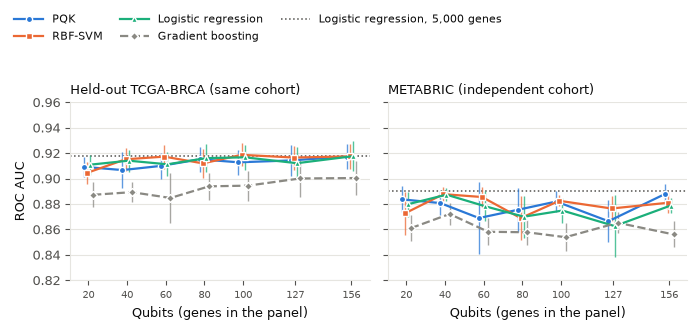

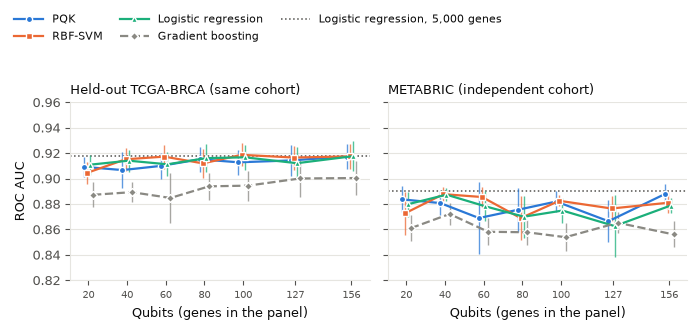

In [2]:
f1 = report.fig_scaling(sweep, paper=True); f1.savefig(OUT / "figures" / "scaling_auc.pdf"); f1

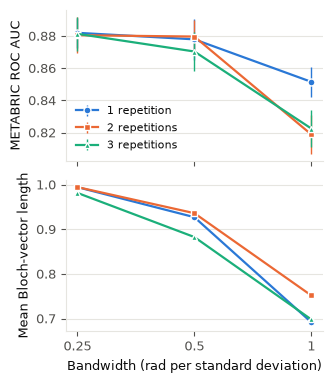

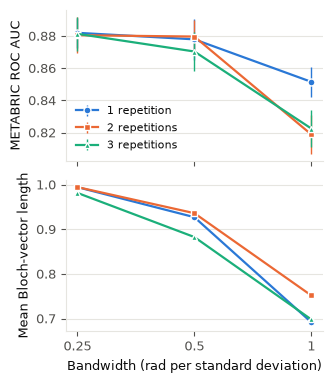

In [3]:
f2 = report.fig_bandwidth(sweep, paper=True); f2.savefig(OUT / "figures" / "bandwidth.pdf"); f2

## Tables

In [4]:
written = paper.write_tables(sweep, results_dir=R, out_dir=OUT / "tables", backend=backend)
for name, text in written.items():
    print(f"--- {name}\n{text}")

--- cohorts.tex
\begin{tabular}{llrrr}
\toprule
Cohort & Platform & Tumors & \textit{TP53} call & Mutated (\%) \\
\midrule
TCGA-BRCA & RNA-seq (RSEM) & 1,082 & 811 & 34.4 \\
METABRIC & Illumina HT-12 microarray & 1,980 & 1,904 & 34.6 \\
\bottomrule
\end{tabular}

--- task_screen.tex
\begin{tabular}{llcccc}
\toprule
 & & \multicolumn{2}{c}{Best single gene} & \multicolumn{2}{c}{156 genes} \\
\cmidrule(lr){3-4}\cmidrule(lr){5-6}
Task & Top gene & TCGA & METABRIC & TCGA & METABRIC \\
\midrule
ER status (IHC) & \textit{ESR1} & 0.957 & 0.957 & 0.951 & 0.941 \\
Luminal A vs B (PAM50) & \textit{SPAG5} & 0.882 & 0.840 & 0.973 & 0.929 \\
TP53 mutation & \textit{TBC1D9} & 0.864 & 0.791 & 0.925 & 0.874 \\
\bottomrule
\end{tabular}

--- main.tex
\begin{tabular}{rcccccccc}
\toprule
 & \multicolumn{4}{c}{Held-out TCGA-BRCA} & \multicolumn{4}{c}{METABRIC} \\
\cmidrule(lr){2-5}\cmidrule(lr){6-9}
Qubits & PQK & RBF-SVM & LogReg & GBM & PQK & RBF-SVM & LogReg & GBM \\
\midrule
20 & 0.909(8) & 0.904(9) &

## Numbers quoted in the text

The LaTeX file reads these as macros from `paper/tables/numbers.tex`, so the prose cannot drift from the data.

In [5]:
print((OUT / "tables" / "numbers.tex").read_text())

% Generated by notebook 5. Do not edit by hand.
\newcommand{\NTcga}{1,082}
\newcommand{\NMeta}{1,980}
\newcommand{\NGenes}{17,139}
\newcommand{\NSeeds}{5}
\newcommand{\Lattice}{ibm\_fez}
\newcommand{\MaxAbsDiff}{0.017}
\newcommand{\SeMin}{0.001}
\newcommand{\SeMax}{0.021}
\newcommand{\SelSmall}{28}
\newcommand{\SelMid}{7}
\newcommand{\SelLarge}{0}
\newcommand{\SelTotal}{35}
\newcommand{\RefIn}{0.918}
\newcommand{\RefExt}{0.890}
\newcommand{\BlochSmallMin}{0.98}
\newcommand{\BlochSmallMax}{0.99}
\newcommand{\BlochLargeMin}{0.69}
\newcommand{\BlochLargeMax}{0.75}
\newcommand{\LossLargeMin}{0.03}
\newcommand{\LossLargeMax}{0.06}
\newcommand{\ConcBloch}{0.06}
\newcommand{\ConcSpread}{0.02}
\newcommand{\GeoMeanMin}{1.1}
\newcommand{\GeoMeanMax}{1.9}
\newcommand{\GeoMax}{8.2}
\newcommand{\EpsCZ}{0.0039}
\newcommand{\ProxyEps}{0.0039}
\newcommand{\ShotUs}{253}
\newcommand{\RepDelayUs}{250}
\newcommand{\CircuitUs}{1.5}
\newcommand{\MinFull}{12}
\newcommand{\MinFullHigh}{47}
\newcommand{\MinPil